In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


In [2]:
data_path = Path("../dataraw/products.csv")

print("Chemin du fichier :", data_path)
print("Le fichier existe :", data_path.exists())


Chemin du fichier : ..\dataraw\products.csv
Le fichier existe : True


In [4]:
df = pd.read_csv(data_path, encoding="utf-8-sig")

print("Dataset importé avec succès !")
df.head()


Dataset importé avec succès !


,product_id,name,domain,category,subcategory,brand,model,description,material,diameter_mm,...,power_kw,voltage_v,dimensions_mm,unit,price_dzd,availability,image_url,source_id,last_verified,notes
0,SH001,Chauffe-Bain 11L Junkers,Chauffage,Chaudière / générateur,Chauffe-bain gaz,JUNKERS,NaN,Chauffe-bain 11 L ; la fiche consultée indique...,NaN,NaN,...,NaN,NaN,NaN,pièce,28500.0,In stock,NaN,SRC001,2026-11-13,Prix et stock affichés par le vendeur au momen...
1,SH002,Chauffe-eau Smart 12L ENERGICAL,Chauffage,Chaudière / générateur,Chauffe-eau gaz,ENERGICAL,Smart 12L,Chauffe-eau 12 L ; variantes de couleur affich...,NaN,NaN,...,NaN,NaN,NaN,pièce,29500.0,In stock,NaN,SRC001,2026-11-13,Prix et stock affichés par le vendeur au momen...
2,SH003,Chaudière ventouse 28 kW Energical,Chauffage,Chaudière / générateur,Chaudière gaz,ENERGICAL,28 kW ventouse,Chaudière ventouse annoncée avec puissance nom...,NaN,NaN,...,28.0,NaN,NaN,pièce,NaN,NaN,NaN,SRC002,2026-11-13,La puissance provient du titre catalogue ; pri...
3,SH004,Accélérateur Grundfos 15-50 75W Réf. 99062433,Chauffage,Pompe de circulation,Circulateur / accélérateur chaudière,Grundfos,15-50,Accélérateur référencé 99062433 ; puissance in...,NaN,NaN,...,NaN,NaN,NaN,pièce,21800.0,NaN,NaN,SRC003,2026-11-13,Vérifier le stock et la compatibilité avec l'a...
4,SH005,Accélérateur Grundfos 15-60 110W Réf. 99157090,Chauffage,Pompe de circulation,Circulateur / accélérateur chaudière,Grundfos,15-60,Accélérateur référencé 99157090 ; puissance in...,NaN,NaN,...,NaN,NaN,NaN,pièce,21300.0,NaN,NaN,SRC003,2026-11-13,Vérifier le stock et la compatibilité avec l'a...


In [9]:
print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])
print("Dimensions du dataset :", df.shape)
print("Colonnes disponibles :")
for column in df.columns:
    print("-", column)

df.info()



Nombre de lignes : 9
Nombre de colonnes : 23
Dimensions du dataset : (9, 23)
Colonnes disponibles :
- product_id
- name
- domain
- category
- subcategory
- brand
- model
- description
- material
- diameter_mm
- length_m
- connection_type
- pressure_rating_bar
- power_kw
- voltage_v
- dimensions_mm
- unit
- price_dzd
- availability
- image_url
- source_id
- last_verified
- notes
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   product_id           9 non-null      object 
 1   name                 9 non-null      object 
 2   domain               9 non-null      object 
 3   category             9 non-null      object 
 4   subcategory          9 non-null      object 
 5   brand                8 non-null      object 
 6   model                7 non-null      object 
 7   description          9 non-null      object 
 8   material     

In [10]:
missing_values = df.isna().sum()

print("Valeurs manquantes par colonne :")
display(missing_values)



Valeurs manquantes par colonne :


product_id             0
name                   0
domain                 0
category               0
subcategory            0
brand                  1
model                  2
description            0
material               9
diameter_mm            9
length_m               9
connection_type        9
pressure_rating_bar    9
power_kw               8
voltage_v              9
dimensions_mm          9
unit                   0
price_dzd              1
availability           7
image_url              9
source_id              0
last_verified          0
notes                  0
dtype: int64

In [11]:
print("Nombre d'identifiants manquants :", df["product_id"].isna().sum())
print("Nombre d'identifiants dupliqués :", df["product_id"].duplicated().sum())

duplicates = df[df["product_id"].duplicated(keep=False)]
display(duplicates)


Nombre d'identifiants manquants : 0
Nombre d'identifiants dupliqués : 0


,product_id,name,domain,category,subcategory,brand,model,description,material,diameter_mm,...,power_kw,voltage_v,dimensions_mm,unit,price_dzd,availability,image_url,source_id,last_verified,notes


In [12]:
domain_counts = df["domain"].value_counts(dropna=False)

display(domain_counts)


domain
Chauffage    8
Plomberie    1
Name: count, dtype: int64

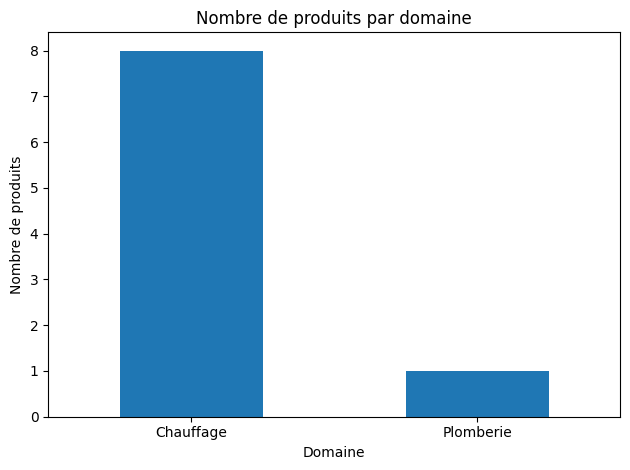

In [13]:
domain_counts.plot(kind="bar", title="Nombre de produits par domaine")

plt.xlabel("Domaine")
plt.ylabel("Nombre de produits")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [14]:
df["price_dzd"] = pd.to_numeric(df["price_dzd"], errors="coerce")

print("Nombre de prix renseignés :", df["price_dzd"].notna().sum())
print("Nombre de prix manquants :", df["price_dzd"].isna().sum())

display(df["price_dzd"].describe())


Nombre de prix renseignés : 8
Nombre de prix manquants : 1


count        8.000000
mean     21237.500000
std       8714.509658
min       1200.000000
25%      21300.000000
50%      22050.000000
75%      25125.000000
max      29500.000000
Name: price_dzd, dtype: float64

In [15]:
for column in ["name", "domain", "category"]:
    print(f"Valeurs manquantes dans {column} :", df[column].isna().sum())


Valeurs manquantes dans name : 0
Valeurs manquantes dans domain : 0
Valeurs manquantes dans category : 0


In [16]:
df_clean = df.copy()

# Retirer les espaces inutiles au début et à la fin des champs texte.
text_columns = df_clean.select_dtypes(include="object").columns

for column in text_columns:
    df_clean[column] = df_clean[column].str.strip()

# Uniformiser les identifiants en texte.
df_clean["product_id"] = df_clean["product_id"].astype("string")


In [17]:
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "products_clean.csv"

df_clean.to_csv(output_path, index=False, encoding="utf-8-sig")

print("Fichier préparé enregistré ici :", output_path)


Fichier préparé enregistré ici : ..\data\processed\products_clean.csv


In [18]:
print("Nombre de produits importés :", len(df))
print("Nombre de produits dans la copie préparée :", len(df_clean))
print("Identifiants uniques :", df_clean["product_id"].nunique())
print("Fichier de sortie créé :", output_path.exists())

display(df_clean.head())


Nombre de produits importés : 9
Nombre de produits dans la copie préparée : 9
Identifiants uniques : 9
Fichier de sortie créé : True


,product_id,name,domain,category,subcategory,brand,model,description,material,diameter_mm,...,power_kw,voltage_v,dimensions_mm,unit,price_dzd,availability,image_url,source_id,last_verified,notes
0,SH001,Chauffe-Bain 11L Junkers,Chauffage,Chaudière / générateur,Chauffe-bain gaz,JUNKERS,NaN,Chauffe-bain 11 L ; la fiche consultée indique...,NaN,NaN,...,NaN,NaN,NaN,pièce,28500.0,In stock,NaN,SRC001,2026-11-13,Prix et stock affichés par le vendeur au momen...
1,SH002,Chauffe-eau Smart 12L ENERGICAL,Chauffage,Chaudière / générateur,Chauffe-eau gaz,ENERGICAL,Smart 12L,Chauffe-eau 12 L ; variantes de couleur affich...,NaN,NaN,...,NaN,NaN,NaN,pièce,29500.0,In stock,NaN,SRC001,2026-11-13,Prix et stock affichés par le vendeur au momen...
2,SH003,Chaudière ventouse 28 kW Energical,Chauffage,Chaudière / générateur,Chaudière gaz,ENERGICAL,28 kW ventouse,Chaudière ventouse annoncée avec puissance nom...,NaN,NaN,...,28.0,NaN,NaN,pièce,NaN,NaN,NaN,SRC002,2026-11-13,La puissance provient du titre catalogue ; pri...
3,SH004,Accélérateur Grundfos 15-50 75W Réf. 99062433,Chauffage,Pompe de circulation,Circulateur / accélérateur chaudière,Grundfos,15-50,Accélérateur référencé 99062433 ; puissance in...,NaN,NaN,...,NaN,NaN,NaN,pièce,21800.0,NaN,NaN,SRC003,2026-11-13,Vérifier le stock et la compatibilité avec l'a...
4,SH005,Accélérateur Grundfos 15-60 110W Réf. 99157090,Chauffage,Pompe de circulation,Circulateur / accélérateur chaudière,Grundfos,15-60,Accélérateur référencé 99157090 ; puissance in...,NaN,NaN,...,NaN,NaN,NaN,pièce,21300.0,NaN,NaN,SRC003,2026-11-13,Vérifier le stock et la compatibilité avec l'a...
